# Stage 5 — Baselines You Must Beat

Before any fancy model, compute the two **dumb** baselines:

1. **Persistence** — `predict(t+h) = log_chl(t)`. No fit, no parameters.
2. **Climatology** — per-pixel day-of-year mean, fit on the training split only.

## Why this matters
At short horizons, *"tomorrow ≈ today"* is shockingly hard to beat. A fancy XGBoost that scores R² = 0.7 sounds impressive — until you discover persistence scores 0.85 at the same horizon, and your model is *worse than doing nothing*.

**The bar:** the ML model in Notebook 6 must beat persistence at H+3 and beyond. At H+1 persistence often wins; that's fine and reportable. PLAN.md: *"beating persistence, not hitting a magic R², is the real bar."*

## Outputs of this notebook
- `data/processed/baseline_scores.csv` — RMSE / R² / N per horizon × method
- `figs/05_baselines.png` — score-vs-horizon plot
- These numbers get re-read by Notebook 6 to compute the persistence delta.

## 5.0 — Load the sample & the feature manifest

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

PROC_DIR = Path("data/processed")
FIG_DIR  = Path("figs")
FIG_DIR.mkdir(parents=True, exist_ok=True)

SAMPLE_PATH   = PROC_DIR / "supervised_sample.parquet"
MANIFEST_PATH = PROC_DIR / "feature_manifest.json"

df = pd.read_parquet(SAMPLE_PATH).sort_values("time").reset_index(drop=True)
with open(MANIFEST_PATH) as f:
    manifest = json.load(f)

HORIZONS = manifest["horizons"]
TARGET_COLS = manifest["target_cols"]

print(f"Rows           : {len(df):,}")
print(f"Time range     : {df.time.min().date()} → {df.time.max().date()}")
print(f"Horizons       : {HORIZONS}")

Rows           : 120,000
Time range     : 2021-01-01 → 2023-12-31
Horizons       : [1, 2, 3, 4, 5, 6, 7]


## 5.1 — Chronological split

Same 70/15/15 split Stage 6 will use, so baseline scores are directly comparable to the model's. **Time-ordered, no shuffle.** A baseline that 'wins' on a shuffled split is meaningless because the model would have seen the test period in training.

In [2]:
cut_train = df["time"].quantile(0.70)
cut_val   = df["time"].quantile(0.85)

train = df[df.time <= cut_train].copy()
val   = df[(df.time > cut_train) & (df.time <= cut_val)].copy()
test  = df[df.time > cut_val].copy()

print(f"train: {train.time.min().date()} → {train.time.max().date()}  ({len(train):,} rows)")
print(f"val  : {val.time.min().date()} → {val.time.max().date()}  ({len(val):,} rows)")
print(f"test : {test.time.min().date()} → {test.time.max().date()}  ({len(test):,} rows)")

train: 2021-01-01 → 2023-02-17  (84,027 rows)
val  : 2023-02-18 → 2023-07-22  (18,074 rows)
test : 2023-07-23 → 2023-12-31  (17,899 rows)


## 5.2 — Persistence baseline

Prediction = the most recent valid observation = `log_chl_t0`. Since we filtered the sample to rows where `log_chl_t0` is valid, the prediction is always defined. The target may still be NaN — we drop those rows from the score (consistent with how Stage 6 will).

Persistence has no parameters and no train/test distinction. We score it on the test split for direct comparability.

In [10]:
from sklearn.metrics import mean_squared_error, r2_score

def score(y_true, y_pred):
    m = y_true.notna() & pd.Series(y_pred, index=y_true.index).notna()
    if m.sum() == 0:
        return dict(rmse=np.nan, r2=np.nan, n=0)
    return dict(
        rmse=float(np.sqrt(mean_squared_error(y_true[m], np.asarray(y_pred)[m.values]))),
        r2  =float(r2_score(y_true[m], np.asarray(y_pred)[m.values])),
        n   =int(m.sum()),
    )

persistence_rows = []
for h in HORIZONS:
    s = score(test[f"target_h{h}"], test["log_chl_t0"].values)
    persistence_rows.append({"method": "persistence", "horizon": h, **s})
    print(f"H+{h}  RMSE={s['rmse']:.4f}  R2={s['r2']:.4f}  N={s['n']:,}")

H+1  RMSE=0.0967  R2=0.8044  N=12,170
H+2  RMSE=0.1094  R2=0.7360  N=11,803
H+3  RMSE=0.1193  R2=0.6904  N=11,411
H+4  RMSE=0.1229  R2=0.6777  N=11,674
H+5  RMSE=0.1287  R2=0.6354  N=10,781
H+6  RMSE=0.1385  R2=0.5738  N=10,748
H+7  RMSE=0.1350  R2=0.6296  N=10,645


## 5.3 — Climatology baseline (from the full CHL cube)

Prediction = per-pixel day-of-year mean of `log10(CHL)`, fit on the **training period of the full original cube** (not the sampled table). The sample has ~3 obs per pixel per DOY — too sparse to be a meaningful climatology (we saw 99.6% test rows missing a lookup in the previous version). The full cube has ~767 training days per pixel, so every pixel × DOY gets a real estimate.

**Leakage control:** restrict the cube to `time ≤ cut_train` before computing the seasonal mean. Test-period observations never enter the climatology.

**Note on coverage:** some pixel × DOY combinations may still be all-NaN in the training period (persistently cloudy days). Those test rows get NaN climatology and drop from the score — same convention persistence uses.

In [11]:
import xarray as xr

# Add DOY to test (sample-side); train doy is no longer used.
test["doy"] = test["time"].dt.dayofyear

# Load the full CHL cube (the one Notebook 1 produced).
chl_full = xr.open_dataset(Path("data/raw/chl_malta_2021_2023.nc")).CHL
log_chl_full = np.log10(chl_full)

# Restrict to training period only — leakage control.
log_chl_train = log_chl_full.sel(time=slice(None, cut_train))
print(f"Training-period cube: {dict(log_chl_train.sizes)}")
print(f"  ({log_chl_train.time.values[0].astype('datetime64[D]')} → "
      f"{log_chl_train.time.values[-1].astype('datetime64[D]')})")

# Per-pixel × DOY mean of log10(CHL), training period only.
clim_da = log_chl_train.groupby("time.dayofyear").mean(skipna=True)
print(f"Climatology cube    : {dict(clim_da.sizes)}  (dayofyear × lat × lon)")

# Flatten to a DataFrame for joining on test.
clim = (clim_da
        .rename({"dayofyear": "doy"})
        .to_dataframe(name="clim_pred")
        .reset_index())
print(f"Climatology rows    : {len(clim):,}")

# Coverage of the lookup.
test_clim = test.merge(clim, on=["latitude", "longitude", "doy"], how="left")
miss = test_clim["clim_pred"].isna().mean()
print(f"Test rows with no climatology lookup: {miss*100:.1f}%")

# Score per horizon.
climatology_rows = []
for h in HORIZONS:
    s = score(test_clim[f"target_h{h}"], test_clim["clim_pred"].values)
    climatology_rows.append({"method": "climatology", "horizon": h, **s})
    print(f"H+{h}  RMSE={s['rmse']:.4f}  R2={s['r2']:.4f}  N={s['n']:,}")

Training-period cube: {'time': 778, 'latitude': 198, 'longitude': 272}
  (2021-01-01 → 2023-02-17)
Climatology cube    : {'dayofyear': 365, 'latitude': 198, 'longitude': 272}  (dayofyear × lat × lon)
Climatology rows    : 19,657,440
Test rows with no climatology lookup: 19.3%
H+1  RMSE=0.1442  R2=0.5269  N=9,900
H+2  RMSE=0.1447  R2=0.5155  N=9,589
H+3  RMSE=0.1428  R2=0.5349  N=9,426
H+4  RMSE=0.1475  R2=0.5150  N=9,388
H+5  RMSE=0.1342  R2=0.5679  N=8,242
H+6  RMSE=0.1400  R2=0.5646  N=8,585
H+7  RMSE=0.1444  R2=0.5712  N=8,676


## 5.4 — Save results & compare

In [12]:
scores = pd.DataFrame(persistence_rows + climatology_rows)
scores.to_csv(PROC_DIR / "baseline_scores.csv", index=False)
print(f"Saved → {PROC_DIR / 'baseline_scores.csv'}")

# tidy pivot for at-a-glance reading
pivot = scores.pivot(index="horizon", columns="method", values=["rmse", "r2"])
pivot.columns = [f"{m}_{w}" for w, m in pivot.columns]
print("\nPersistence vs Climatology (test split):")
print(pivot.round(4).to_string())

Saved → data\processed\baseline_scores.csv

Persistence vs Climatology (test split):
         climatology_rmse  persistence_rmse  climatology_r2  persistence_r2
horizon                                                                    
1                  0.1442            0.0967          0.5269          0.8044
2                  0.1447            0.1094          0.5155          0.7360
3                  0.1428            0.1193          0.5349          0.6904
4                  0.1475            0.1229          0.5150          0.6777
5                  0.1342            0.1287          0.5679          0.6354
6                  0.1400            0.1385          0.5646          0.5738
7                  0.1444            0.1350          0.5712          0.6296


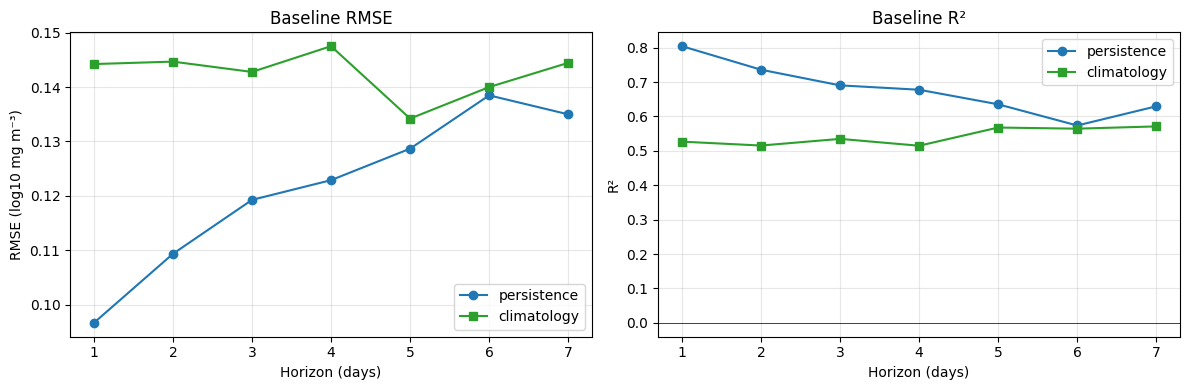

In [13]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for method, marker, color in [("persistence", "o", "#1f77b4"),
                              ("climatology", "s", "#2ca02c")]:
    sub = scores[scores.method == method].sort_values("horizon")
    axes[0].plot(sub.horizon, sub.rmse, marker=marker, color=color, label=method)
    axes[1].plot(sub.horizon, sub.r2,   marker=marker, color=color, label=method)

axes[0].set_xlabel("Horizon (days)"); axes[0].set_ylabel("RMSE (log10 mg m⁻³)")
axes[0].set_title("Baseline RMSE");   axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].set_xlabel("Horizon (days)"); axes[1].set_ylabel("R²")
axes[1].set_title("Baseline R²");     axes[1].legend(); axes[1].grid(alpha=0.3)
axes[1].axhline(0, color="k", linewidth=0.5)

plt.tight_layout()
plt.savefig(FIG_DIR / "05_baselines.png", dpi=150)
plt.show()

---
## Validation Gate 5

Three things to confirm:

1. Persistence R² is **recorded** for every horizon.
2. Persistence **decays** from H+1 to H+7 (a flat or rising curve is a red flag — suggests target/feature misalignment that Gate 4 missed).
3. You have **written down the bar**: the ML model in Notebook 6 must beat persistence at H+3, H+4, …, H+7. At H+1 and H+2 persistence often wins; that is normal.

In [14]:
pers = scores[scores.method == "persistence"].sort_values("horizon")

results = {}
results["persistence R² recorded for every horizon"] = pers["r2"].notna().all()

r2s = pers["r2"].values
# Allow a small uptick noise within a step but require the H+1 to H+7 trend to decay
results["persistence R² decays H+1 → H+7"] = r2s[0] > r2s[-1]

results["persistence H+1 R² in plausible range (0.4–0.95)"] = 0.4 <= r2s[0] <= 0.95

for name, ok in results.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

print("\nThe bar for Notebook 6:")
for _, r in pers.iterrows():
    print(f"  H+{int(r.horizon)}  beat RMSE < {r.rmse:.4f}   /   R² > {r.r2:.4f}")

if all(results.values()):
    print("\nGate 5 PASSED — proceed to 06-XGBoost-Chrono.")
else:
    print("\nGate 5 FAILED — common causes:")
    print("  • R² flat across horizons → leakage. Re-run Gate 4 alignment assert.")
    print("  • H+1 R² < 0.4 → unusually noisy data. Check that the sample isn't dominated by gappy pixels.")

PASS  persistence R² recorded for every horizon
PASS  persistence R² decays H+1 → H+7
PASS  persistence H+1 R² in plausible range (0.4–0.95)

The bar for Notebook 6:
  H+1  beat RMSE < 0.0967   /   R² > 0.8044
  H+2  beat RMSE < 0.1094   /   R² > 0.7360
  H+3  beat RMSE < 0.1193   /   R² > 0.6904
  H+4  beat RMSE < 0.1229   /   R² > 0.6777
  H+5  beat RMSE < 0.1287   /   R² > 0.6354
  H+6  beat RMSE < 0.1385   /   R² > 0.5738
  H+7  beat RMSE < 0.1350   /   R² > 0.6296

Gate 5 PASSED — proceed to 06-XGBoost-Chrono.


---
## Next: `06-XGBoost-Chrono.ipynb`

Trains XGBoost per horizon with native NaN handling and a strict chronological split (same cuts as this notebook). The training script reads `baseline_scores.csv` at the end so it can report the **delta vs persistence** directly. That delta is what we'll cite in the eventual writeup, not the raw R².